# 06 · Options américaines et arbre binomial

> 📘 Notebook compagnon du cours [Les grecques en finance](https://pgu.github.io/pi-gamma-upsilon/). Le code Python reproduit ce que font les playgrounds du site, avec les **mêmes conventions de desk** : vega par point de vol, theta par jour, rho par point de taux.
>
> **Installation** (une fois) : `pip install -r requirements.txt`, puis `jupyter lab`. Lance ce notebook depuis le dossier `notebooks/`.

**Leçon liée :** « Options américaines & exercice anticipé ».

**Objectifs :** valoriser par arbre binomial (CRR), vérifier la convergence vers Black-Scholes, mesurer la **prime d'exercice anticipé** et tracer la frontière d'exercice optimal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import greeks as g          # notre petite bibliothèque (voir greeks.py)

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format

## 1. L'arbre converge vers Black-Scholes

Pour une option européenne, plus on met de pas, plus l'arbre se rapproche de la formule fermée.

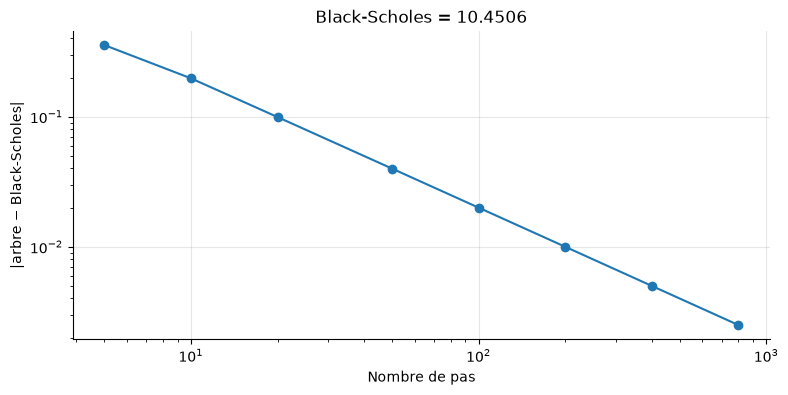

In [2]:
kw = dict(S=100, K=100, T=1, r=0.05, sigma=0.20, kind="call")
bs = float(g.price(**kw))
steps = [5, 10, 20, 50, 100, 200, 400, 800]
errors = [abs(g.binomial(**kw, steps=n, american=False) - bs) for n in steps]

fig, ax = plt.subplots()
ax.loglog(steps, errors, "o-")
ax.set(xlabel="Nombre de pas", ylabel="|arbre − Black-Scholes|", title=f"Black-Scholes = {bs:.4f}");

## 2. Américain vs européen : un put très ITM

Put K = 100, 1 an, r = 5 %, σ = 25 %.

Prime d'exercice anticipé max : 4.851 (au spot 50)


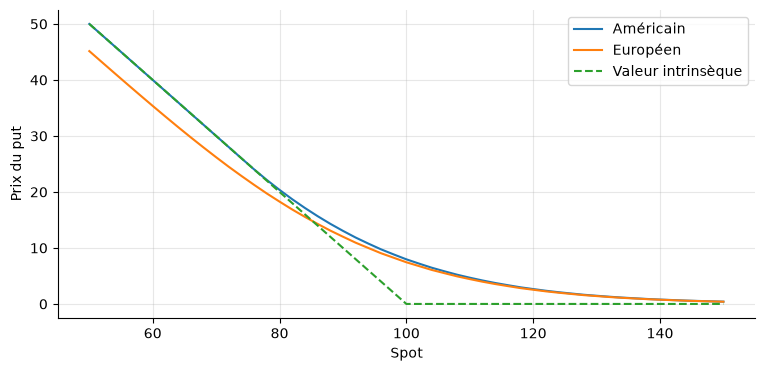

In [3]:
kw = dict(K=100, T=1, r=0.05, sigma=0.25, kind="put")
spots = np.arange(50, 151, 2.0)
am = np.array([g.binomial(S=s, **kw, american=True) for s in spots])
eu = np.array([g.binomial(S=s, **kw, american=False) for s in spots])
intr = np.maximum(100 - spots, 0)

fig, ax = plt.subplots()
ax.plot(spots, am, label="Américain"); ax.plot(spots, eu, label="Européen"); ax.plot(spots, intr, "--", label="Valeur intrinsèque")
ax.set(xlabel="Spot", ylabel="Prix du put"); ax.legend()
print(f"Prime d'exercice anticipé max : {np.max(am - eu):.3f} (au spot {spots[np.argmax(am - eu)]:.0f})")

## 3. La frontière d'exercice optimal

Le spot **critique** S\* en dessous duquel le put américain vaut exactement sa valeur intrinsèque (il faut l'exercer). Plus les taux sont élevés, plus S\* est haut : recevoir le strike tôt rapporte plus d'intérêts.

In [4]:
def critical_spot(r, T=1.0, K=100, sigma=0.25):
    grid = np.arange(30, 100.5, 0.5)
    vals = np.array([g.binomial(S=s, K=K, T=T, r=r, sigma=sigma, kind="put", steps=200) - max(K - s, 0) for s in grid])
    ex = grid[vals < 1e-6]
    return float(ex.max()) if len(ex) else float("nan")

rates = [0.0, 0.01, 0.02, 0.04, 0.06, 0.08]
pd.DataFrame({"taux r": rates, "spot critique S*": [critical_spot(r) for r in rates]})

,taux r,spot critique S*
0,0.0000,NaN
1,0.0100,62.5000
2,0.0200,67.5000
3,0.0400,73.5000
4,0.0600,77.0000
5,0.0800,79.5000


À r = 0 il n'y a **aucun intérêt à gagner** en exerçant tôt : l'exercice anticipé n'est jamais optimal (S\* indéfini ou très bas).

## 4. Le cas du call avec dividende

Sans dividende, un call américain vaut un call européen. Avec un dividende continu élevé, l'exercice anticipé du call devient intéressant pour un call très ITM.

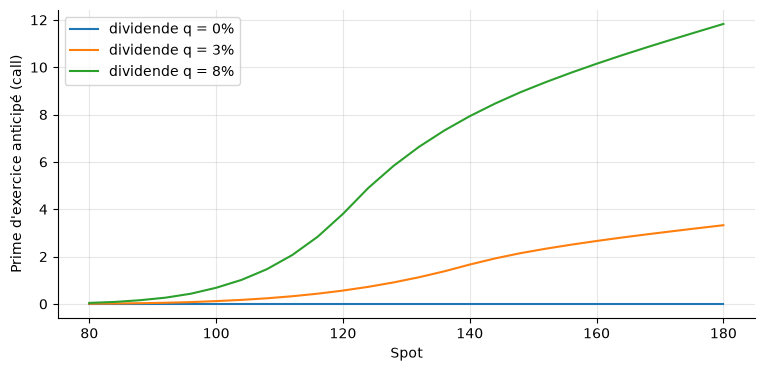

In [5]:
kw = dict(K=100, T=1, r=0.02, sigma=0.20, kind="call")
spots = np.arange(80, 181, 4.0)
fig, ax = plt.subplots()
for q in (0.0, 0.03, 0.08):
    prem = [g.binomial(S=s, **kw, q=q, american=True) - g.binomial(S=s, **kw, q=q, american=False) for s in spots]
    ax.plot(spots, prem, label=f"dividende q = {q:.0%}")
ax.set(xlabel="Spot", ylabel="Prime d'exercice anticipé (call)"); ax.legend();

### À toi de jouer

1. Compare le delta d'un put américain très ITM (calculé par bump du spot sur l'arbre : `(binomial(S+h) − binomial(S−h)) / (2h)`) avec le delta Black-Scholes : lequel est le plus proche de −1 ?
2. Mesure le temps de calcul de `binomial` pour 150, 500 et 2 000 pas. Comment grandit-il ? (L'arbre est en O(n²).)
3. *(Avancé)* Compare avec QuantLib (`pip install QuantLib`) sur le même put américain.